In [1]:

# Importing required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Setting the plotting style
sns.set_style("whitegrid")

# Setting default figure size
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:

# Uploading the dataset

from google.colab import files

uploaded = files.upload()


Saving train.csv to train (1).csv


In [4]:

df = pd.read_csv("train (1).csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [5]:

print("Dataset Shape:", df.shape)


Dataset Shape: (1460, 81)


In [6]:

# Displaying the first five rows of the dataset

df.head()


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [7]:

# Checking dataset information

df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:

# Checking missing values in each column

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])


LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


In [9]:

# Counting columns with missing values

total_missing_columns = df.isnull().any().sum()

print("Total columns with missing values:", total_missing_columns)


Total columns with missing values: 19


### Step 1: Observations

- The dataset contains 1,460 rows and 81 columns.
- The dataset contains numerical and categorical variables.
- There are 19 columns with missing values.
- Some missing values indicate the absence of features such as pools, fences and fireplaces.
- The dataset is ready for further exploratory analysis after understanding its data quality.

In [10]:

# Identifying numerical columns

numeric_cols = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numeric_cols)

print("\nTotal Numerical Columns:", len(numeric_cols))


Numerical Columns:
Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

Total Numerical Columns: 38


In [11]:

# Identifying categorical columns

categorical_cols = df.select_dtypes(include="object").columns

print("Categorical Columns:")
print(categorical_cols)

print("\nTotal Categorical Columns:", len(categorical_cols))


Categorical Columns:
Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object')

Total Categorical Columns: 43


### Step 2: Observations

- The dataset contains 38 numerical columns and 43 categorical columns.
- Numerical columns include SalePrice, LotArea, GrLivArea and YearBuilt.
- Categorical columns include Neighborhood, HouseStyle, MSZoning and SaleCondition.
- Some columns, such as OverallQual, represent ordered categories even though they are stored as numerical values.

In [12]:
# Descriptive statistics of numerical columns

df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [13]:
# Central tendency of SalePrice

print("Mean Sale Price:", df["SalePrice"].mean())
print("Median Sale Price:", df["SalePrice"].median())
print("Mode Sale Price:", df["SalePrice"].mode()[0])

Mean Sale Price: 180921.19589041095
Median Sale Price: 163000.0
Mode Sale Price: 140000


In [14]:
# Spread of SalePrice

print("Standard Deviation:", df["SalePrice"].std())
print("Variance:", df["SalePrice"].var())

Standard Deviation: 79442.50288288663
Variance: 6311111264.297451


In [15]:
# Range and Interquartile Range (IQR)

price_range = df["SalePrice"].max() - df["SalePrice"].min()

Q1 = df["SalePrice"].quantile(0.25)
Q3 = df["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

print("Range:", price_range)
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Range: 720100
Q1: 129975.0
Q3: 214000.0
IQR: 84025.0


In [16]:
# Skewness and Kurtosis of SalePrice

print("Skewness:", df["SalePrice"].skew())
print("Kurtosis:", df["SalePrice"].kurt())

Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529


In [17]:
# Frequency of houses in each neighborhood

print(df["Neighborhood"].value_counts())

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64


### Step 3: Descriptive Statistics – Observations

- The average house sale price is approximately 180,921.
- The median sale price is 163,000, while the mode is 140,000.
- The standard deviation is 79,442.50, showing considerable variation in house prices.
- The SalePrice distribution is positively skewed, with a skewness of 1.88.
- The kurtosis is 6.54, indicating heavier tails than a normal distribution.
- The IQR of house prices is 84,025.
- NAmes has the highest number of houses (225), while Blueste has the lowest (2).

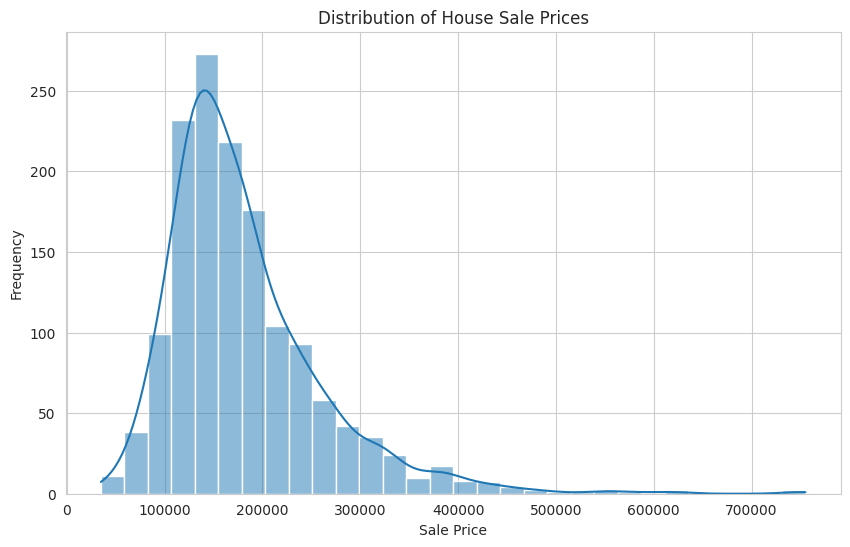

In [18]:
# Distribution of SalePrice

plt.figure(figsize=(10, 6))

sns.histplot(df["SalePrice"], bins=30, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

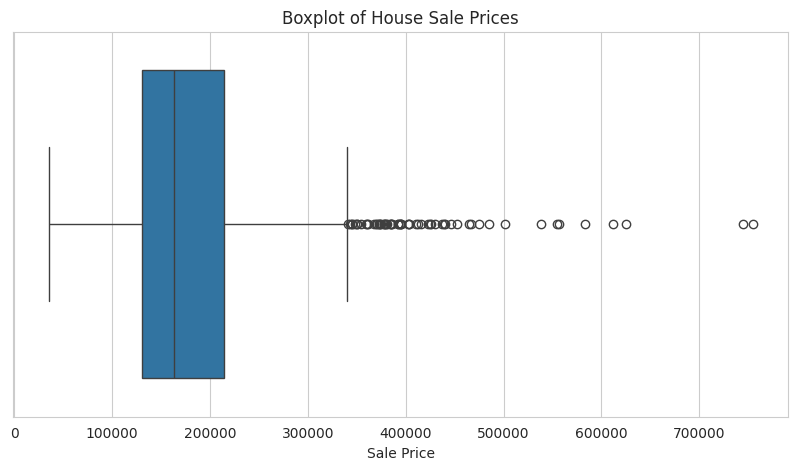

In [19]:
# Boxplot of SalePrice

plt.figure(figsize=(10, 5))

sns.boxplot(x=df["SalePrice"])

plt.title("Boxplot of House Sale Prices")
plt.xlabel("Sale Price")

plt.show()

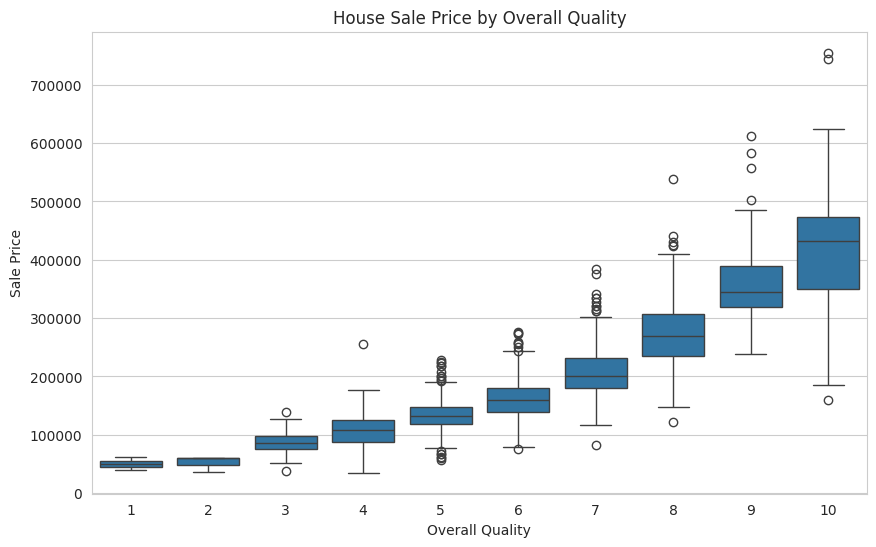

In [20]:
# Sale Price by Overall Quality

plt.figure(figsize=(10, 6))

sns.boxplot(x="OverallQual", y="SalePrice", data=df)

plt.title("House Sale Price by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

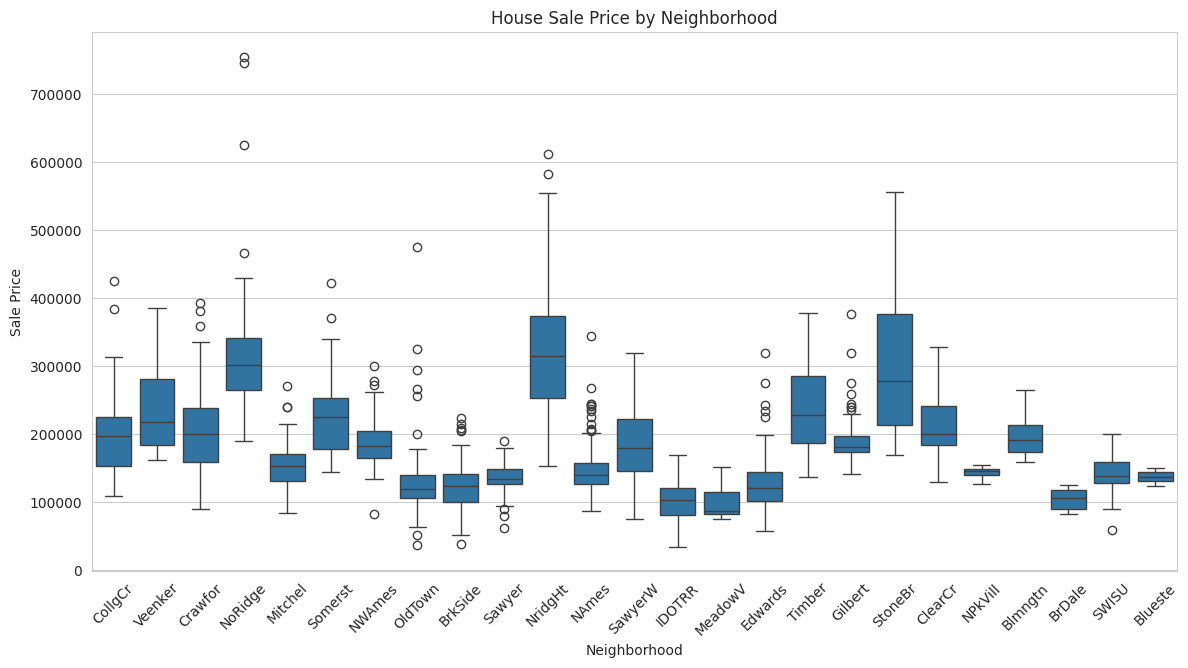

In [21]:
# Sale Price by Neighborhood

plt.figure(figsize=(14, 7))

sns.boxplot(x="Neighborhood", y="SalePrice", data=df)

plt.title("House Sale Price by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")

plt.xticks(rotation=45)

plt.show()

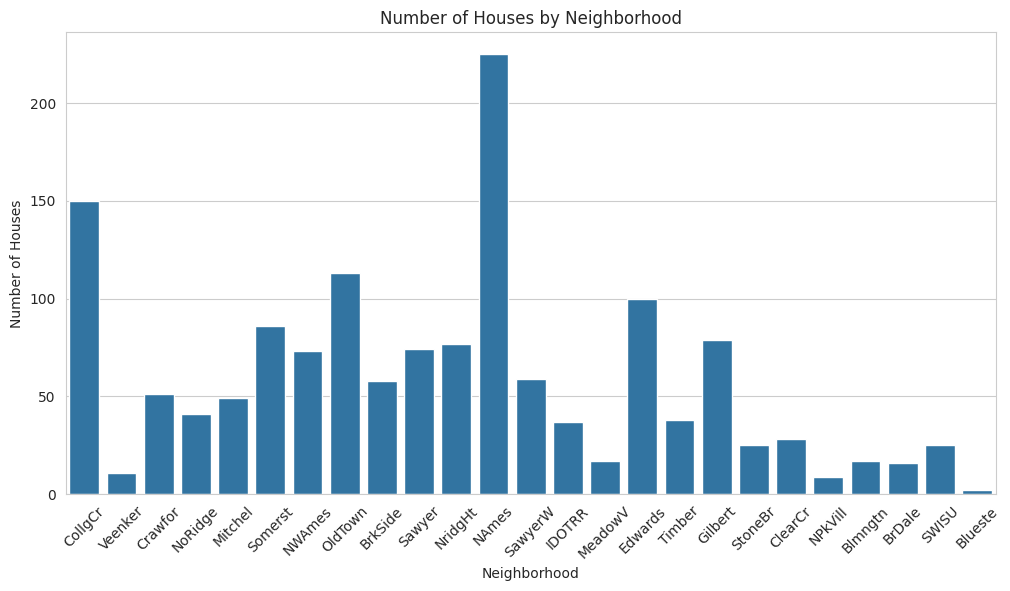

In [22]:
# Count of houses in each neighborhood

plt.figure(figsize=(12, 6))

sns.countplot(x="Neighborhood", data=df)

plt.title("Number of Houses by Neighborhood")
plt.xlabel("Neighborhood")
plt.ylabel("Number of Houses")

plt.xticks(rotation=45)

plt.show()

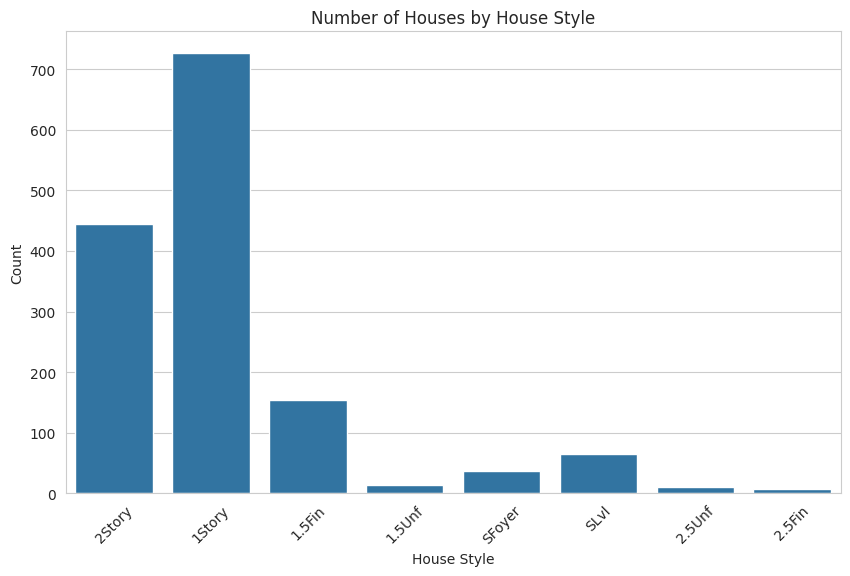

In [23]:
 # Count of houses by House Style

plt.figure(figsize=(10, 6))

sns.countplot(x="HouseStyle", data=df)

plt.title("Number of Houses by House Style")
plt.xlabel("House Style")
plt.ylabel("Count")

plt.xticks(rotation=45)

plt.show()

### Step 4: Data Visualization – Observations

- The SalePrice histogram shows a positively skewed distribution.
- The SalePrice boxplot helps identify potential outliers.
- Houses with higher OverallQual generally have higher sale prices.
- Sale prices vary across different neighborhoods.
- NAmes has the highest number of houses in the dataset.
- HouseStyle visualization shows the distribution of different house styles.

In [24]:
# Correlation between numerical variables

correlation = df.select_dtypes(include=np.number).corr()

print(correlation["SalePrice"].sort_values(ascending=False))

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

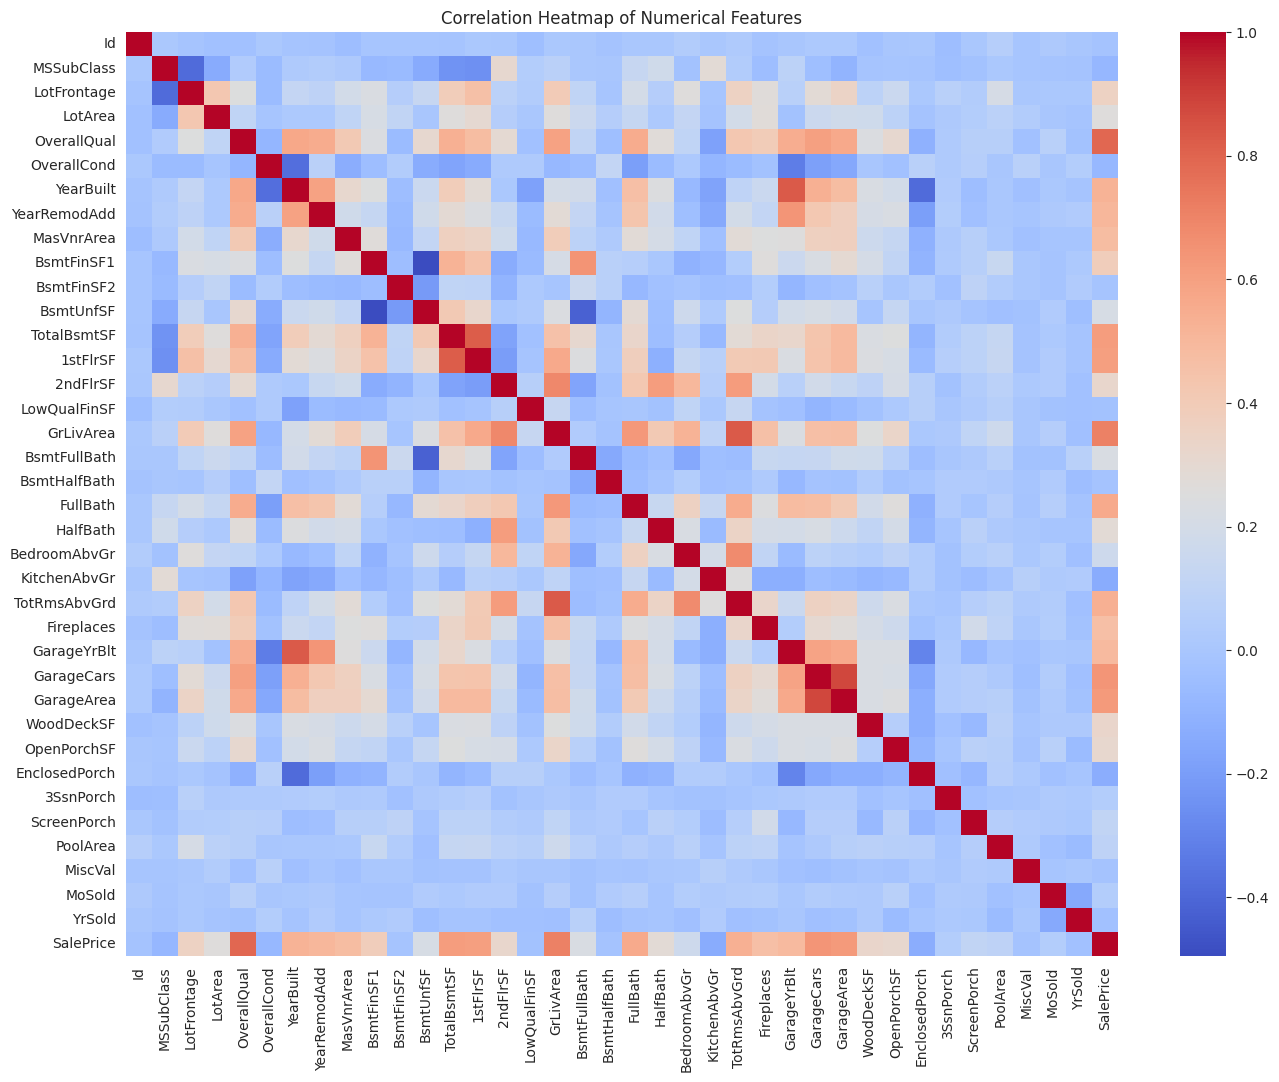

In [25]:
# Correlation Heatmap

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

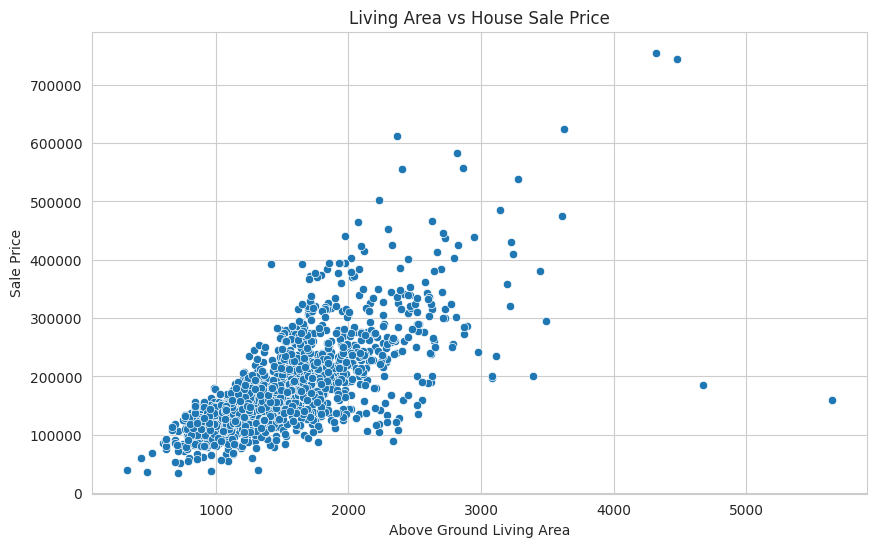

In [26]:
# Scatter Plot: Living Area vs Sale Price

plt.figure(figsize=(10, 6))

sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)

plt.title("Living Area vs House Sale Price")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")

plt.show()

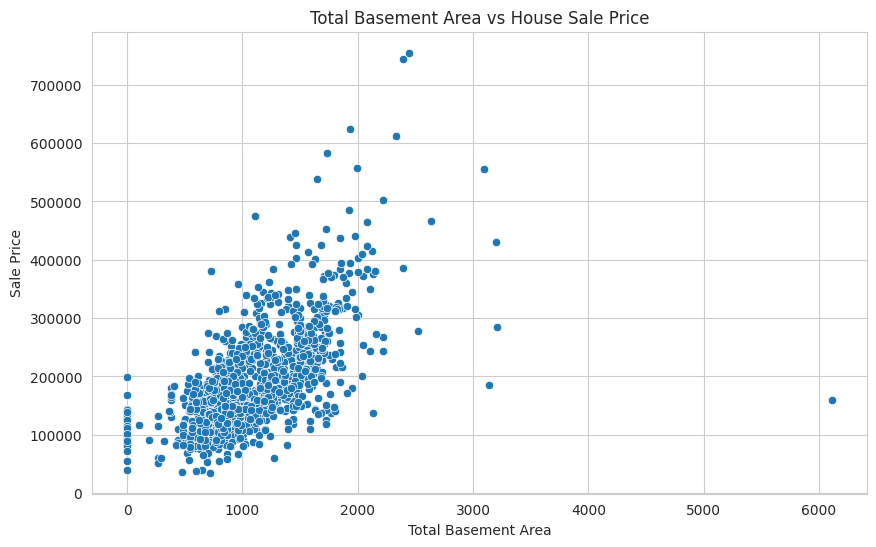

In [27]:
# Scatter Plot: Basement Area vs Sale Price

plt.figure(figsize=(10, 6))

sns.scatterplot(x="TotalBsmtSF", y="SalePrice", data=df)

plt.title("Total Basement Area vs House Sale Price")
plt.xlabel("Total Basement Area")
plt.ylabel("Sale Price")

plt.show()

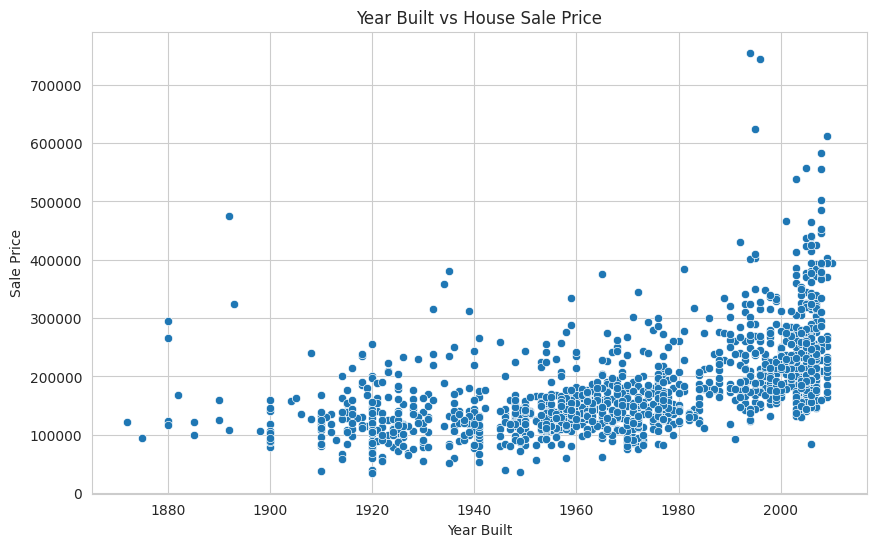

In [28]:
# Scatter Plot: Year Built vs Sale Price

plt.figure(figsize=(10, 6))

sns.scatterplot(x="YearBuilt", y="SalePrice", data=df)

plt.title("Year Built vs House Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")

plt.show()

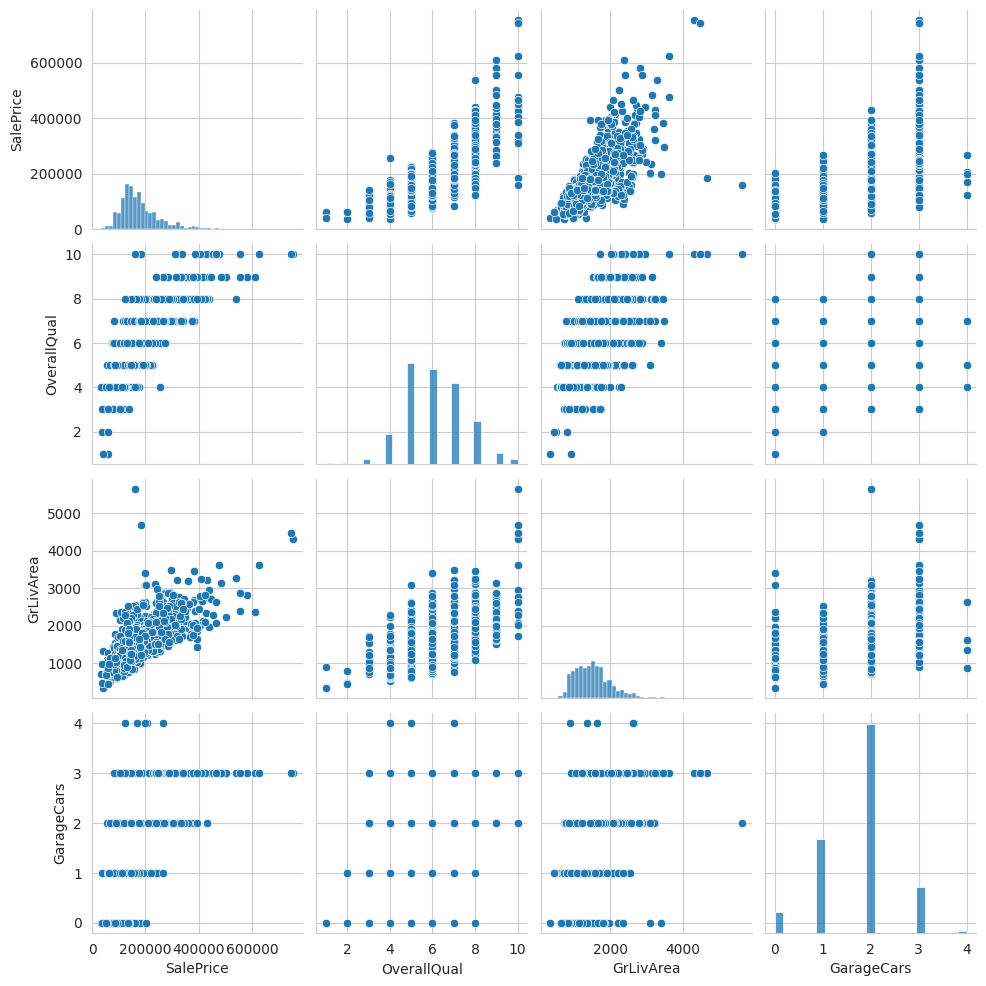

In [29]:
# Pairplot of important numerical features

selected_features = ["SalePrice", "OverallQual", "GrLivArea", "GarageCars"]

sns.pairplot(df[selected_features])

plt.show()

In [30]:
# Detecting outliers using IQR method

Q1 = df["SalePrice"].quantile(0.25)
Q3 = df["SalePrice"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

outliers = df[
    (df["SalePrice"] < lower_limit) |
    (df["SalePrice"] > upper_limit)
]

print("Number of Outliers:", len(outliers))

Lower Limit: 3937.5
Upper Limit: 340037.5
Number of Outliers: 61


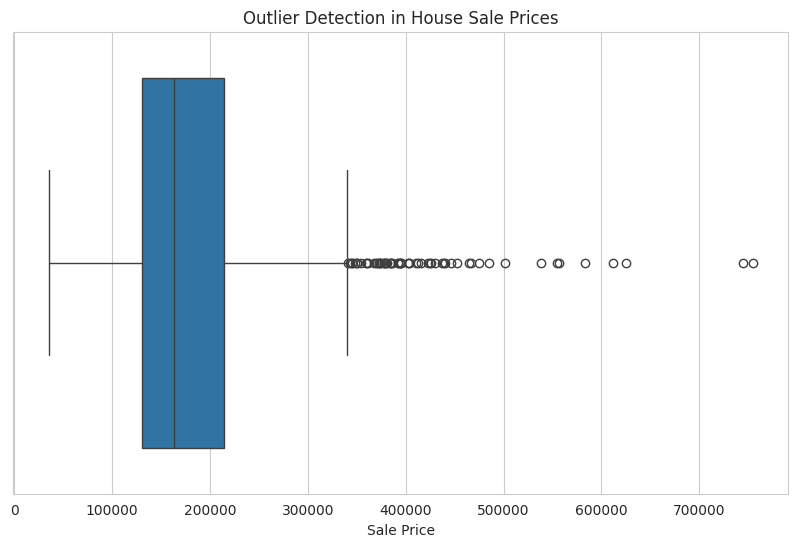

In [31]:
# Boxplot to visualize SalePrice outliers

plt.figure(figsize=(10, 6))

sns.boxplot(x=df["SalePrice"])

plt.title("Outlier Detection in House Sale Prices")
plt.xlabel("Sale Price")

plt.show()

In [32]:
# Detecting outliers using Z-score

z_scores = np.abs(stats.zscore(df["SalePrice"]))

z_outliers = df[z_scores > 3]

print("Number of Z-score Outliers:", len(z_outliers))

Number of Z-score Outliers: 22


In [33]:
# Comparing IQR and Z-score outliers

print("IQR Outliers:", len(outliers))
print("Z-score Outliers:", len(z_outliers))

IQR Outliers: 61
Z-score Outliers: 22


### Step 7: Outlier Detection – Observations

- The IQR method identified 61 potential outliers in SalePrice.
- The Z-score method identified 22 potential outliers.
- The IQR method detected more outliers than the Z-score method.
- Outliers may represent unusually expensive houses rather than incorrect data.
- Therefore, outliers should be investigated before removing them.

In [34]:
# Checking duplicate rows

print("Number of Duplicate Rows:", df.duplicated().sum())

Number of Duplicate Rows: 0


In [35]:
# Total missing values in dataset

print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 7829


In [36]:
# Missing values in each column

missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


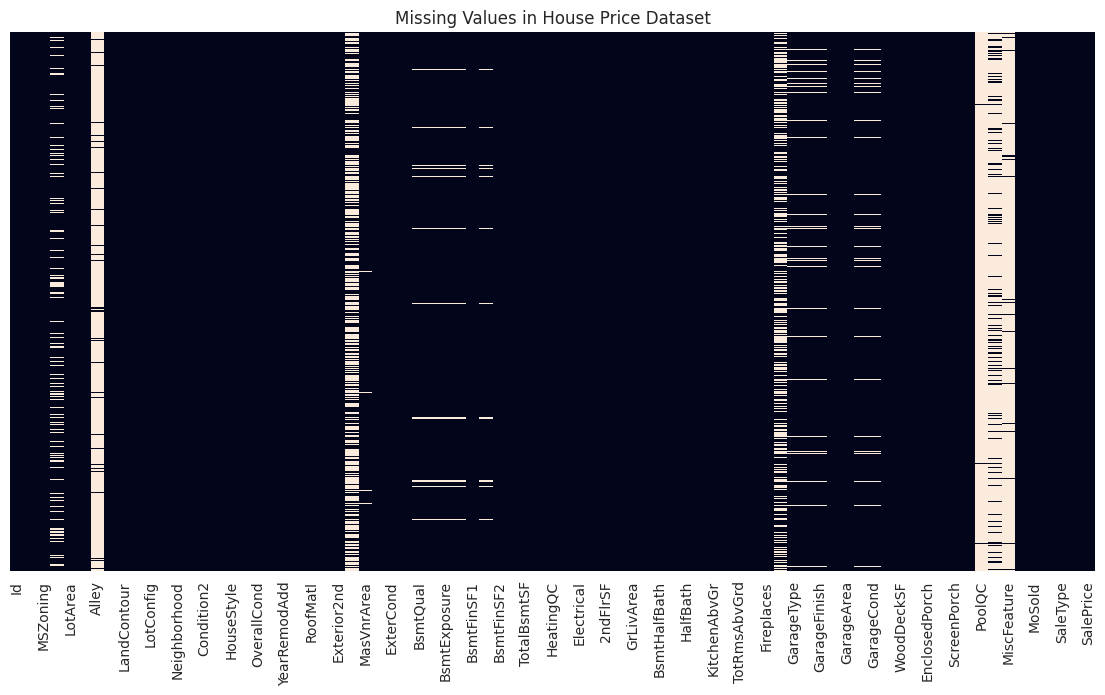

In [37]:
# Missing Values Heatmap

plt.figure(figsize=(14, 7))

sns.heatmap(df.isnull(), cbar=False, yticklabels=False)

plt.title("Missing Values in House Price Dataset")

plt.show()

### Step 8: Data Quality – Observations

- The dataset contains 7,829 missing values.
- Missing values are present in 19 columns.
- PoolQC has the highest number of missing values (1,453).
- MiscFeature and Alley also contain a large number of missing values.
- Some missing values indicate the absence of a particular house feature.
- No duplicate rows were found in the dataset.
- Missing values should be handled carefully before further analysis.

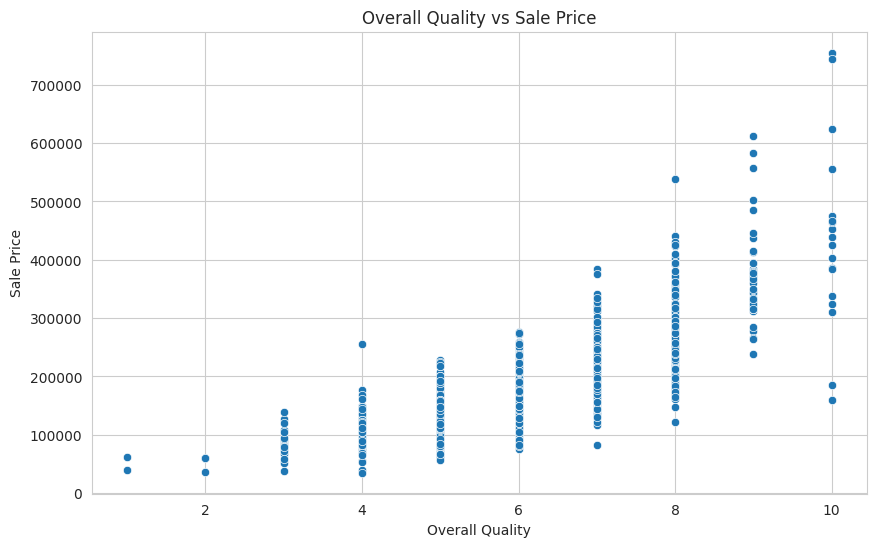

In [38]:
# Relationship between Overall Quality and Sale Price

plt.figure(figsize=(10, 6))

sns.scatterplot(x="OverallQual", y="SalePrice", data=df)

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

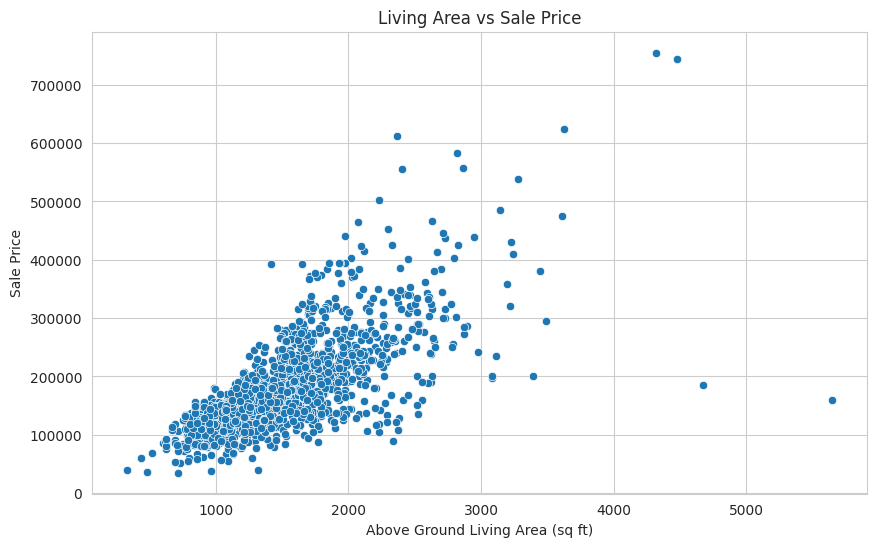

In [39]:
# Relationship between Living Area and Sale Price

plt.figure(figsize=(10, 6))

sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)

plt.title("Living Area vs Sale Price")
plt.xlabel("Above Ground Living Area (sq ft)")
plt.ylabel("Sale Price")

plt.show()

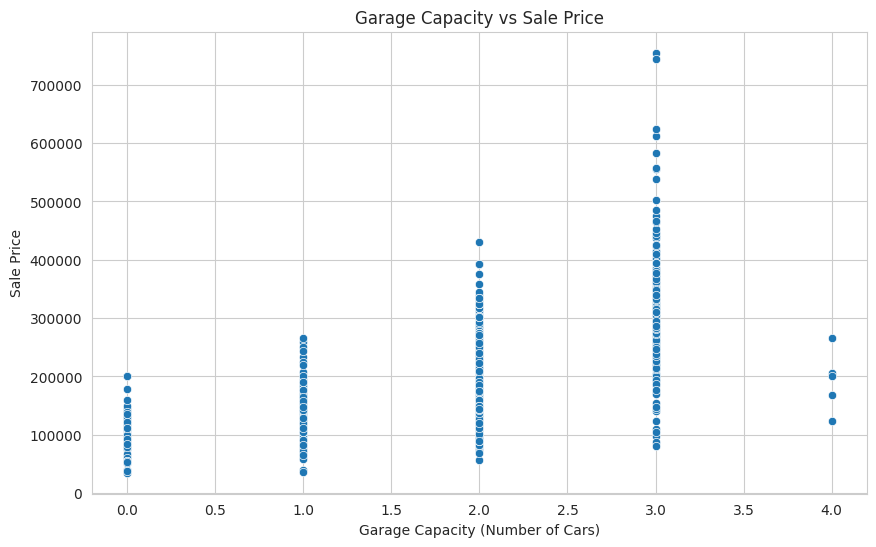

In [40]:
# Relationship between Garage Capacity and Sale Price

plt.figure(figsize=(10, 6))

sns.scatterplot(x="GarageCars", y="SalePrice", data=df)

plt.title("Garage Capacity vs Sale Price")
plt.xlabel("Garage Capacity (Number of Cars)")
plt.ylabel("Sale Price")

plt.show()

### Step 9: Relationship Between Numerical Features – Observations

- OverallQual shows a positive relationship with SalePrice.
- Houses with higher living areas generally have higher sale prices.
- Garage capacity also shows a positive relationship with SalePrice.
- OverallQual appears to have a strong relationship with house prices.
- These relationships show association, not necessarily causation.

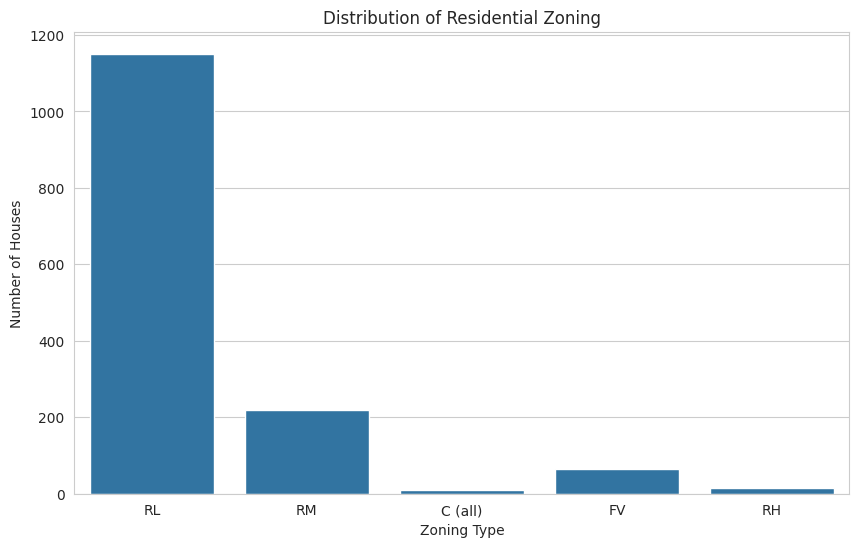

In [41]:
# Distribution of Residential Zoning

plt.figure(figsize=(10, 6))

sns.countplot(x="MSZoning", data=df)

plt.title("Distribution of Residential Zoning")
plt.xlabel("Zoning Type")
plt.ylabel("Number of Houses")

plt.show()

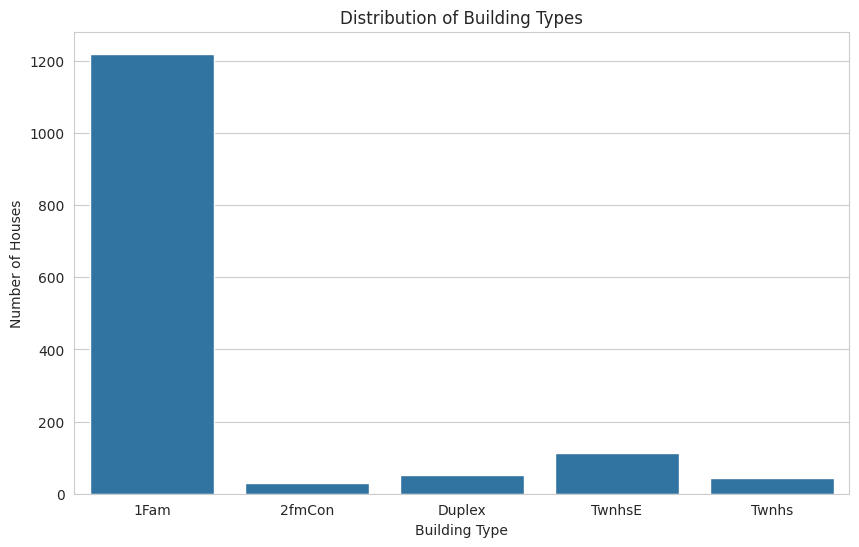

In [42]:
# Distribution of Building Types

plt.figure(figsize=(10, 6))

sns.countplot(x="BldgType", data=df)

plt.title("Distribution of Building Types")
plt.xlabel("Building Type")
plt.ylabel("Number of Houses")

plt.show()

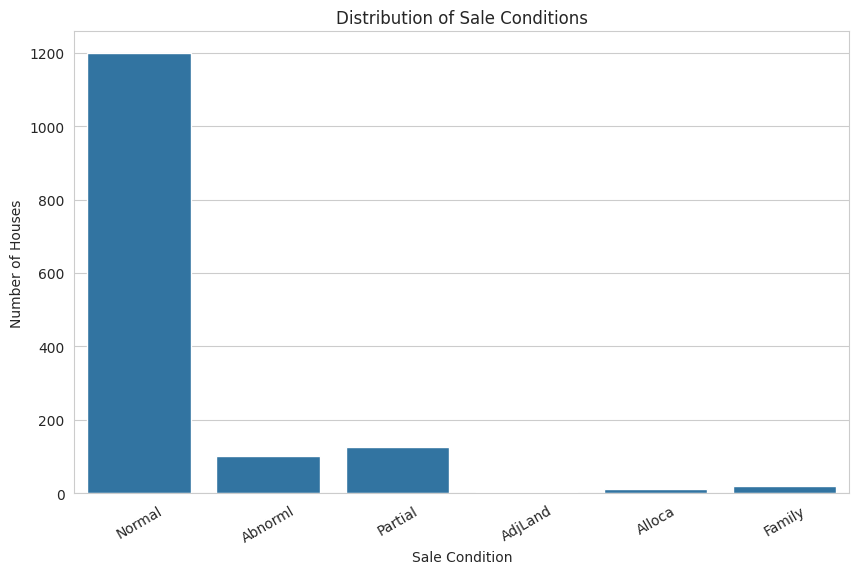

In [43]:
# Distribution of Sale Conditions

plt.figure(figsize=(10, 6))

sns.countplot(x="SaleCondition", data=df)

plt.title("Distribution of Sale Conditions")
plt.xlabel("Sale Condition")
plt.ylabel("Number of Houses")

plt.xticks(rotation=30)

plt.show()

### Step 10: Categorical Feature Analysis – Observations

- MSZoning shows the distribution of houses across different zoning categories.
- Building types show that the dataset contains different types of residential properties.
- SaleCondition shows the different conditions under which houses were sold.
- These visualizations help us understand the distribution of categorical features.
- Some categories have more houses than others.

In [44]:
# Average Sale Price by Overall Quality

quality_price = df.groupby("OverallQual")["SalePrice"].mean()

print(quality_price)

OverallQual
1      50150.000000
2      51770.333333
3      87473.750000
4     108420.655172
5     133523.347607
6     161603.034759
7     207716.423197
8     274735.535714
9     367513.023256
10    438588.388889
Name: SalePrice, dtype: float64


In [45]:
# Average Sale Price by Neighborhood

neighborhood_price = df.groupby("Neighborhood")["SalePrice"].mean()

print(neighborhood_price.sort_values(ascending=False))

Neighborhood
NoRidge    335295.317073
NridgHt    316270.623377
StoneBr    310499.000000
Timber     242247.447368
Veenker    238772.727273
Somerst    225379.837209
ClearCr    212565.428571
Crawfor    210624.725490
CollgCr    197965.773333
Blmngtn    194870.882353
Gilbert    192854.506329
NWAmes     189050.068493
SawyerW    186555.796610
Mitchel    156270.122449
NAmes      145847.080000
NPkVill    142694.444444
SWISU      142591.360000
Blueste    137500.000000
Sawyer     136793.135135
OldTown    128225.300885
Edwards    128219.700000
BrkSide    124834.051724
BrDale     104493.750000
IDOTRR     100123.783784
MeadowV     98576.470588
Name: SalePrice, dtype: float64


### Step 11: Statistical Analysis – Observations

- Average sale price generally increases with OverallQual.
- Quality rating 10 has the highest average sale price.
- Quality rating 1 has the lowest average sale price.
- NoRidge has the highest average sale price among neighborhoods.
- MeadowV has the lowest average sale price among neighborhoods.
- House prices vary across different neighborhoods and quality ratings.

# Final Conclusion

- The Ames Housing Dataset contains 1,460 rows and 81 columns.
- The dataset includes both numerical and categorical features.
- The average house sale price is approximately 180,921.
- SalePrice is positively skewed, meaning a smaller number of expensive houses affect the distribution.
- OverallQual and GrLivArea have strong positive correlations with SalePrice.
- House prices vary across different neighborhoods.
- The IQR method identified 61 potential outliers.
- The dataset contains 7,829 missing values and no duplicate rows.
- Higher-quality houses generally have higher average sale prices.
- Data visualization and statistical analysis helped identify important patterns and relationships.

## Learning Outcome

Through this project, I learned how to explore a dataset using Python, Pandas, NumPy, Matplotlib and Seaborn. I also learned how to calculate descriptive statistics, visualize data, identify missing values and outliers, and understand relationships between different features.

In [46]:
print("Dataset Shape:", df.shape)

print("Total Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("Total Numerical Columns:", len(df.select_dtypes(include=np.number).columns))

print("Total Categorical Columns:", len(df.select_dtypes(include="object").columns))

Dataset Shape: (1460, 81)
Total Missing Values: 7829
Duplicate Rows: 0
Total Numerical Columns: 38
Total Categorical Columns: 43
